# Lab 02 — PCA, SVD and orthogonal projection of $(X_{\mathrm{train}}$)
### From vectors to principal components — theory and Python

**Audience:** L3 / M1 / M2 / Engineering school · **Indicative duration:** 2 h – 2 h 45 · **Hardware:** CPU, no external dataset.

**Objectives:** understand orthogonal projection, compute an SVD, retrieve PCA from centered $(X_{\mathrm{train}}$), project new observations without data leakage, reconstruct and quantify the error. We will use a 2D cloud and the **Digits 8×8** handwritten digits dataset from `scikit-learn`.

**Notation and convention:** one row = one observation; one column = one feature. Thus $(X_{\rm train}\in\mathbb R^{n\times d}$).

> Note: PCA is a **linear projection** method. It will be our mathematical starting point before the lecture on non-linear autoencoders.

## 0. Essential Notions

1. **Dot product**: $(\langle a,b\rangle=a^\top b)$.
2. **Euclidean norm**: $(\|x\|_2^2=x^\top x)$.
3. **Orthogonality**: $(r\perp v\iff r^\top v=0)$.
4. **Projection onto a subspace** spanned by $(V_k\in\mathbb R^{d\times k})$ whose columns are orthonormal:

$[
\boxed{P_k=V_kV_k^\top,\quad \widehat x=P_k x \quad\text{(column vectors)}}.
]$

For a **row-wise** dataset, centered by the train mean $\(\mu\)$:

$[
\boxed{\widehat X=(X-\mathbf 1\mu^\top)V_kV_k^\top+\mathbf1\mu^\top}.
]$

Orthogonal projection minimizes the distance to the subspace. The residual is orthogonal to this subspace.

## 1. Imports

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(42)
np.set_printoptions(precision=4, suppress=True)
print('Prêt : NumPy', np.__version__)

Prêt : NumPy 2.1.3


## 2. Orthogonal projection: first in 2D

We project a vector $x\in\mathbb R^2$ onto the line spanned by a unit vector $v$.

$[
\widehat x=(x^\top v)v,\quad r=x-\widehat x,\quad r^\top v=0.
]$

x = [3. 2.] 
v = [0.8944 0.4472] 
Projection = [3.2 1.6] 
Résidu = [-0.2  0.4]
Produit scalaire résidu · v = 3.0531133177191805e-16


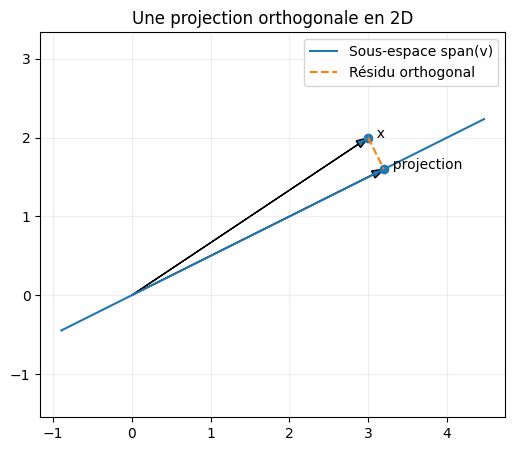

In [ ]:
x = np.array([3.0, 2.0])
v = np.array([2.0, 1.0])
v = v/np.linalg.norm(v)  # base orthonormale (divide by the norme)
proj = (x @ v)*v
residual = x-proj

print('x =', x, '\nv =', v, '\nProjection =', proj, '\nRésidu =', residual)
print('Produit scalaire résidu · v =', residual @ v)
assert np.isclose(residual @ v, 0, atol=1e-12)

line = np.linspace(-1, 5, 100)
points = np.outer(line, v)
plt.figure(figsize=(6,5))
plt.plot(points[:,0],points[:,1],label='Sous-espace span(v)')
plt.arrow(0,0,x[0],x[1],head_width=.10,length_includes_head=True)
plt.arrow(0,0,proj[0],proj[1],head_width=.10,length_includes_head=True)
plt.plot([x[0],proj[0]],[x[1],proj[1]],'--',label='Résidu orthogonal')
plt.scatter([x[0],proj[0]],[x[1],proj[1]])
plt.text(x[0],x[1],'  x')
plt.text(proj[0],proj[1],'  projection')
plt.axis('equal'); plt.grid(alpha=.2); plt.legend(); plt.title('Une projection orthogonale en 2D')
plt.show()

### 2.1 Projection matrix: three testable properties

$
P^\top=P,\qquad P^2=P,\qquad (x-Px)^\top v=0.
$

For \(k\) orthonormal principal directions, replace $\(vv^\top\)$ with $\(V_kV_k^\top\)$.

In [ ]:
P = np.outer(v,v)
print('Matrice P :\n', P)
print('Symétrie ||P-P.T|| =', np.linalg.norm(P-P.T))
print('Idempotence ||P²-P|| =', np.linalg.norm(P@P-P))
print('rang(P) =', np.linalg.matrix_rank(P))
assert np.allclose(P.T, P)
assert np.allclose(P@P, P)
assert np.allclose(P@x, proj)

Matrice P :
 [[0.8 0.4]
 [0.4 0.2]]
Symétrie ||P-P.T|| = 0.0
Idempotence ||P²-P|| = 1.3877787807814457e-16
rang(P) = 1


## 3. PCA: looking for the line that best explains the data

Suppose we have 2D data concentrated around a main direction. We look for the unit vector \(v_1\) that maximizes the projected variance:

$\
\boxed{v_1=\arg\max_{\|v\|=1}\,v^\top Sv},
\qquad
S=\frac1{n-1}X_c^\top X_c.
\
$

The solution is the eigenvector of the covariance matrix associated with the largest eigenvalue.

Moyenne = [ 4.9617 -2.0446]
Covariance =
 [[6.2449 3.9748]
 [3.9748 2.8037]]
Valeurs propres = [8.8555 0.1931]
Variance expliquée PC1 = 0.9786613720645619


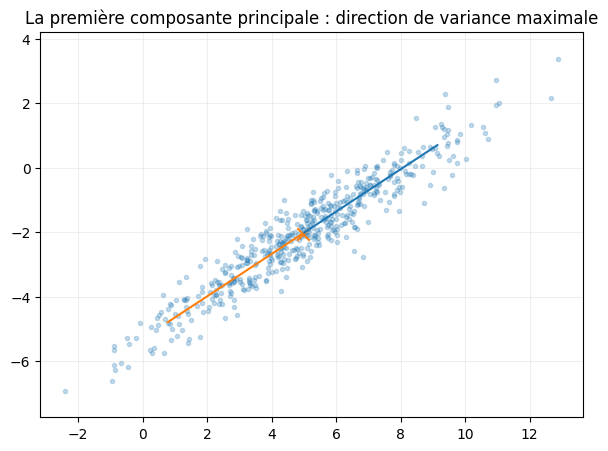

In [ ]:
# Nuage allongé et tourné
n = 500
Z = rng.normal(size=(n,2)) * np.array([3.0,0.45])
angle = np.deg2rad(32)
R = np.array([[np.cos(angle),-np.sin(angle)],
              [np.sin(angle), np.cos(angle)]])
X = Z@R.T + np.array([5.0,-2.0])

mu = X.mean(axis=0)
Xc = X-mu
S = Xc.T@Xc/(n-1)
eigenvalues, eigenvectors = np.linalg.eigh(S)
order = np.argsort(eigenvalues)[::-1]
eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:,order]
v1 = eigenvectors[:,0]

print('Moyenne =', mu)
print('Covariance =\n', S)
print('Valeurs propres =', eigenvalues)
print('Variance expliquée PC1 =', eigenvalues[0]/eigenvalues.sum())

plt.figure(figsize=(7,5))
plt.scatter(X[:,0],X[:,1],alpha=.25,s=9)
for scale in [-5,5]:
    endpoint=mu+scale*v1
    plt.plot([mu[0],endpoint[0]],[mu[1],endpoint[1]])
plt.scatter(*mu,marker='x',s=80)
plt.axis('equal'); plt.title('La première composante principale : direction de variance maximale')
plt.grid(alpha=.2); plt.show()

## 4. SVD — Singular Value Decomposition

Any real matrix $(X_c\in\mathbb R^{n\times d})$ admits a decomposition

$
\boxed{X_c=U\Sigma V^\top},
$

where the columns of \(U\) and \(V\) are orthonormal (thin SVD form) and \($\Sigma\$) contains the singular values \(s_1\ge s_2\ge\cdots\ge0\).

The essential identity for PCA:

$
\underbrace{S}_{\text{covariance}}=\frac{X_c^\top X_c}{n-1}
=V\underbrace{\frac{\Sigma^2}{n-1}}_{\text{eigenvalues}}V^\top.
$

**Conclusion:** the **right singular vectors** (columns of $(V)$) are the principal directions. The principal variances are $(s_j^2/(n-1)$).

In [ ]:
U, singular_values, Vt = np.linalg.svd(Xc, full_matrices=False)
V = Vt.T
X_rebuilt = (U*singular_values)@Vt
variances_svd = singular_values**2/(n-1)
print('Shapes : Xc', Xc.shape, 'U', U.shape,
      's', singular_values.shape, 'Vt', Vt.shape)
print('Erreur SVD :', np.linalg.norm(Xc-X_rebuilt))
print('Variances par SVD :', variances_svd)
print('Valeurs propres covariance :', eigenvalues)
assert np.allclose(X_rebuilt,Xc)
assert np.allclose(variances_svd,eigenvalues)

Shapes : Xc (500, 2) U (500, 2) s (2,) Vt (2, 2)
Erreur SVD : 3.138404781569024e-14
Variances par SVD : [8.8555 0.1931]
Valeurs propres covariance : [8.8555 0.1931]


## 5. Optimal rank-\(k\) approximation (Eckart–Young)

We keep the first \(k\) singular values:

$
X_{c,k}=U_k\Sigma_kV_k^\top
=\underbrace{X_cV_k}_{Z_k}\,V_k^\top.
$

**Two equivalent viewpoints**:

- **Projection / reconstruction**: $(Z_k=X_cV_k)$ then $(\widehat X_c=Z_kV_k^\top)$.
- **Truncated SVD**: $(\widehat X_c=U_k\Sigma_kV_k^\top)$.

In terms of the Frobenius norm, this rank-\(k\) approximation is optimal. Its squared error is

$
\|X_c-X_{c,k}\|_F^2=\sum_{j>k}s_j^2.
$

In [ ]:
k=1
Vk = V[:,:k]
Zk = Xc@Vk
Xc_hat_proj = Zk@Vk.T
Xc_hat_svd = (U[:,:k]*singular_values[:k])@Vt[:k,:]

print('Erreur de reconstruction (Frobenius²) :',np.linalg.norm(Xc-Xc_hat_proj,'fro')**2)
print('Somme s_j² omis :',np.sum(singular_values[k:]**2))
print('Orthogonalité résidu aux PC :',np.linalg.norm((Xc-Xc_hat_proj)@Vk))
assert np.allclose(Xc_hat_proj,Xc_hat_svd)
assert np.isclose(np.linalg.norm(Xc-Xc_hat_proj,'fro')**2,
                  np.sum(singular_values[k:]**2))
assert np.allclose((Xc-Xc_hat_proj)@Vk,0,atol=1e-10)

Erreur de reconstruction (Frobenius²) : 96.34913586457141
Somme s_j² omis : 96.34913586457137
Orthogonalité résidu aux PC : 1.0644631699944874e-14


## 6. From $(X_{\mathrm{train}})$ to the projection of $(X_{\mathrm{test}})$

For a real machine learning task, it is essential to follow this protocol:

1. Split the data into `train` and `test` sets.
2. Compute **the mean on the train set only**: $(\mu_{\rm train})$.
3. Center $(X_{\rm train}$), perform the SVD, and keep $(V_k)$.
4. Project **both train and test using the exact same mean and directions**.

$
\boxed{Z_{\rm test}=(X_{\rm test}-\mu_{\rm train})V_k},
\qquad
\boxed{\widehat X_{\rm test}=Z_{\rm test}V_k^\top+\mu_{\rm train}}.
$

Computing PCA axes on the test set (or before the split) would create **data leakage**.

### 6.1 Dataset: Digits handwritten characters (8 × 8)

Train: (1437, 64) Test: (360, 64)


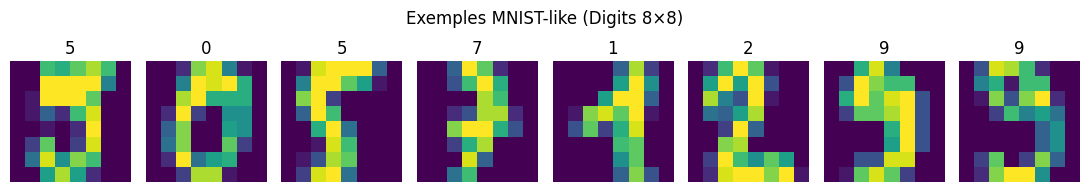

In [ ]:
digits = load_digits()
images=digits.images
X_all=digits.data.astype(np.float64)  # 1797 lignes, 64 colonnes
y_all=digits.target
X_train, X_test, y_train, y_test = train_test_split(
    X_all,y_all,test_size=.2,random_state=42,stratify=y_all)

print('Train:',X_train.shape,'Test:',X_test.shape)
fig, ax=plt.subplots(1,8,figsize=(11,2))
for i in range(8):
    ax[i].imshow(X_train[i].reshape(8,8))
    ax[i].set_title(str(y_train[i])); ax[i].axis('off')
plt.suptitle('Exemples MNIST-like (Digits 8×8)')
plt.tight_layout(); plt.show()

### 6.2 "From scratch" PCA on centered `X_train`

In [ ]:
mu_train = X_train.mean(axis=0,keepdims=True)
X_train_centered = X_train - mu_train
X_test_centered  = X_test  - mu_train  # même moyenne !

U_train,s_train,Vt_train=np.linalg.svd(X_train_centered,full_matrices=False)
V_train=Vt_train.T
explained_variances=s_train**2/(len(X_train)-1)
explained_ratios=explained_variances/explained_variances.sum()
cum_explained=np.cumsum(explained_ratios)

print('X_train centered :',X_train_centered.shape)
print('U,S,Vt :',U_train.shape,s_train.shape,Vt_train.shape)
print('Variance cumulée avec 10 composantes :',cum_explained[9])
assert np.allclose(X_train_centered.mean(axis=0),0,atol=1e-10)

plt.figure(figsize=(8,4))
plt.plot(np.arange(1,len(cum_explained)+1),cum_explained,marker='.',markersize=3)
plt.axhline(.90,linestyle='--',label='90 %')
plt.axhline(.95,linestyle=':',label='95 %')
plt.xlabel('Nombre de composantes k')
plt.ylabel('Variance cumulée expliquée')
plt.title('Combien de composantes principales conserver ?')
plt.grid(alpha=.2);plt.legend();plt.show()

### 6.3 Projection, reconstruction and residual orthogonality

In [ ]:
def project_and_reconstruct(X, mu, V, k):
    Vk=V[:,:k]
    centered=X-mu
    Z=centered@Vk
    Xhat=Z@Vk.T+mu
    return Z,Xhat

k=16
Z_train, Xhat_train=project_and_reconstruct(X_train,mu_train,V_train,k)
Z_test, Xhat_test=project_and_reconstruct(X_test,mu_train,V_train,k)

train_mse=np.mean((X_train-Xhat_train)**2)
test_mse=np.mean((X_test-Xhat_test)**2)
Vk=V_train[:,:k]
residual_test=X_test-Xhat_test

print('Projection train:',Z_train.shape,'Projection test:',Z_test.shape)
print('MSE train:',train_mse,'MSE test:',test_mse)
print('Orthogonalité ||(X_test - Xhat_test)V_k|| =',np.linalg.norm(residual_test@Vk))

P=Vk@Vk.T
assert np.allclose(P,P.T,atol=1e-10)
assert np.allclose(P@P,P,atol=1e-10)
assert np.allclose(residual_test@Vk,0,atol=1e-9)
assert np.allclose(X_train,Z_train@Vk.T+mu_train + (X_train-Xhat_train))

### 6.4 Reconstruction quality as a function of $(k)$

We evaluate the reconstruction of $(X_{\mathrm{test}})$ without ever recomputing the axes on the test set.

In [ ]:
ks=[1,2,5,10,16,24,32,48,64]
rows=[]
for ki in ks:
    _,rec=project_and_reconstruct(X_test,mu_train,V_train,ki)
    rows.append({'k':ki,'MSE test':np.mean((X_test-rec)**2),
                 'Variance train expliquée':cum_explained[ki-1]})
results=pd.DataFrame(rows)
display(results.round(4))

plt.figure(figsize=(7,4))
plt.plot(results['k'],results['MSE test'],marker='o')
plt.xlabel('k : dimension projetée')
plt.ylabel('MSE reconstruction sur test')
plt.title('Compression vs fidélité')
plt.grid(alpha=.2);plt.show()

### 6.5 Visualizing reconstructions

In [ ]:
idx=3
fig, axes=plt.subplots(1,6,figsize=(11,2.4))
axes[0].imshow(X_test[idx].reshape(8,8))
axes[0].set_title('Original')
for j,ki in enumerate([2,5,10,20,40],start=1):
    _,x_hat=project_and_reconstruct(X_test[idx:idx+1],mu_train,V_train,ki)
    axes[j].imshow(x_hat[0].reshape(8,8))
    axes[j].set_title(f'PCA k={ki}')
for a in axes:a.axis('off')
plt.tight_layout();plt.show()

### 6.6 2D Latent Representation

In [ ]:
Z2,_=project_and_reconstruct(X_test,mu_train,V_train,2)
plt.figure(figsize=(7,5))
sc=plt.scatter(Z2[:,0],Z2[:,1],c=y_test,s=16,alpha=.65)
plt.colorbar(sc,label='Chiffre')
plt.xlabel('Composante principale 1')
plt.ylabel('Composante principale 2')
plt.title('Coordonnées latentes 2D (PCA train, projection test)')
plt.grid(alpha=.15);plt.show()

## 7. Comparison with `sklearn.decomposition.PCA`

The signs of individual eigenvectors may change: \(v\) and \(-v\) represent the same direction. Therefore, we should compare **subspaces / reconstructions**, rather than the raw coefficients one by one.

In [ ]:
k=16
pca_sk=PCA(n_components=k,svd_solver='full')
pca_sk.fit(X_train)  # jamais fit sur le test !
Z_sk=pca_sk.transform(X_test)
Xhat_sk=pca_sk.inverse_transform(Z_sk)
_,Xhat_ours=project_and_reconstruct(X_test,mu_train,V_train,k)

print('Erreur max entre reconstructions :',np.max(np.abs(Xhat_sk-Xhat_ours)))
print('MSE sklearn :',mean_squared_error(X_test,Xhat_sk))
print('MSE SVD perso:',mean_squared_error(X_test,Xhat_ours))
assert np.allclose(Xhat_sk,Xhat_ours,atol=1e-8)

## 8. Essential identities must be mastered

For centered $(X_{\rm train})$:

$
X_c=U\Sigma V^\top,\qquad
S=\frac{X_c^\top X_c}{n-1}=V\frac{\Sigma^2}{n-1}V^\top.
$

For $(V_k^\top V_k=I_k)$:

$
\boxed{P_k=V_kV_k^\top},\quad P_k=P_k^\top,\quad P_k^2=P_k.
$

And:

$
\boxed{Z_{\rm train}=X_cV_k},\quad
\boxed{\widehat X_{\rm train}=Z_{\rm train}V_k^\top+\mu_{\rm train}},
$

and the residual $(R=X_c-X_cV_kV_k^\top)$ satisfies $(RV_k=0)$.

**Fundamental distinction:** $(P_k)$ acts on the **feature space** $((d\times d))$. The projection of the samples is done by multiplying the centered matrix on the **right**.

## 9. Exercises to complete

**Exercise 1 — Geometry.** For $(v=(1,2,2)^\top 3)$ and $(x=(3,0,0)^\top)$, compute the projection $(\widehat x)$ and verify the orthogonality of the residual.

**Exercise 2 — SVD.** For a centered matrix of your choice, verify numerically that $(X_c^\top X_c=V\Sigma^2V^\top\$.

**Exercise 3 — Train projection.** Find the minimum $(k)$ explaining at least 90% of the training variance.

**Exercise 4 — Residual.** Numerically compare $(\|X_c-X_{c,k}\|_F^2)$to $(\sum_{j>k}s_j^2)$ on Digits.

**Exercise 5 — Data leakage.** Explain why `PCA.fit(X_test)` is incorrect to measure the performance of a trained representation.

**Exercise 6 — Autoencoder Bridge.** With $(k=16)$, conceptually compare $(X_cV_kV_k^\top)$ to $(g_\theta(f_\phi(X)))$. What part becomes non-linear?

In [ ]:
# Gabarit d'exercice : remplacez les ... par vos calculs
# v = np.array([1,2,2])/3
# x = np.array([3,0,0])
# xhat = ...
# print(xhat, (x-xhat)@v)

# k90 = ...
# print('k minimal 90 % :', k90)

## 10. Solutions: hints and numerical controls

<details><summary><b>Show guided answers</b></summary>

1. \(x^\top v=1\), so \(\widehat x=v=(1/3,2/3,2/3)\).
2. `np.allclose(Xc.T@Xc, V@np.diag(s**2)@V.T)`.
3. `np.searchsorted(cum_explained, 0.90) + 1`.
4. The Eckart–Young theorem yields the expected equality.
5. Learning axes on the test set introduces information from unseen data into the model.
6. PCA uses an encoder \(x\mapsto (x-\mu)V_k\) and a decoder \(z\mapsto zV_k^\top+\mu\), both of which are linear/affine; the AE can learn two non-linear networks.

</details>

In [ ]:
# Contrôles de corrigé
v3 = np.array([1.,2.,2.])/3
x3 = np.array([3.,0.,0.])
x3hat = (x3@v3)*v3
k90 = int(np.searchsorted(cum_explained, .90)+1)

assert np.allclose(x3hat,[1/3,2/3,2/3])
assert np.isclose((x3-x3hat)@v3, 0)
assert cum_explained[k90-1] >= .90
assert k90 == 1 or cum_explained[k90-2] < .90
assert np.allclose(X_train_centered.T@X_train_centered,
                   V_train@np.diag(s_train**2)@V_train.T,atol=1e-7)
print('Ex.1 : projection =',x3hat)
print('Ex.3 : k minimal à 90 % =',k90)
print('Ex.2 : identité SVD vérifiée')

## 11. Summary — Why start with PCA before the Autoencoder?

PCA:
$
X_c\xrightarrow{\times V_k}Z_k\xrightarrow{\times V_k^\top}\widehat X_c.
$

Autoencoder:
$
X\xrightarrow{f_\phi}Z\xrightarrow{g_\theta}\widehat X.
$

**Same objective:** how to keep useful information in a smaller space?

**Main difference:** PCA learns an **optimal linear subspace for MSE**; the AE learns a **potentially non-linear** representation. The VAE will later add a sampleable latent distribution.